This is a similar notebook to another, but here we warmstart a nonconvex IAS solve using a convex one.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from solvers import GKSIAS

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
#A = jlinops.IdentityOperator((n,n))
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

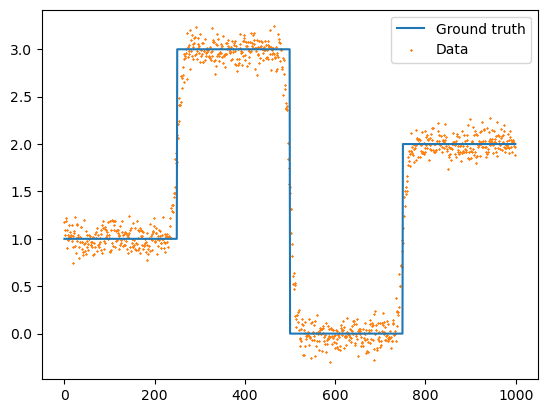

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

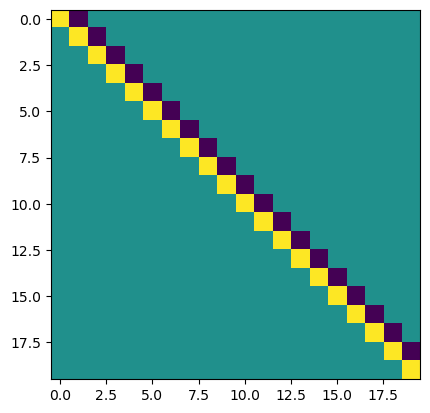

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Use solver

In [26]:
init_gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=noise_var)
init_data = init_gksias_solver.solve(n_iter=150, hyperpr_r=1.0, hyperpr_beta=1.5 + 1e-5, x_true=ground_truth, regparam="dp3", x0=None, tol=1e-5)

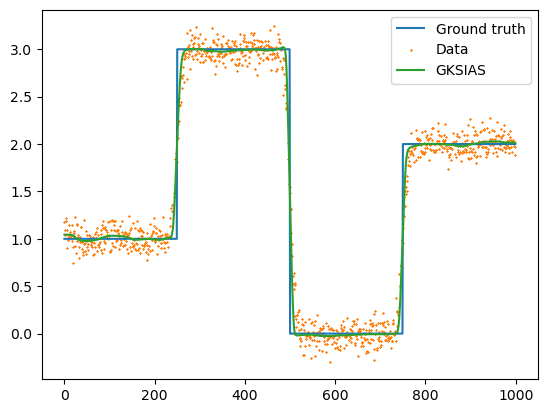

In [27]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, init_data["x"], label="GKSIAS", color="C2")
plt.legend()
plt.show()

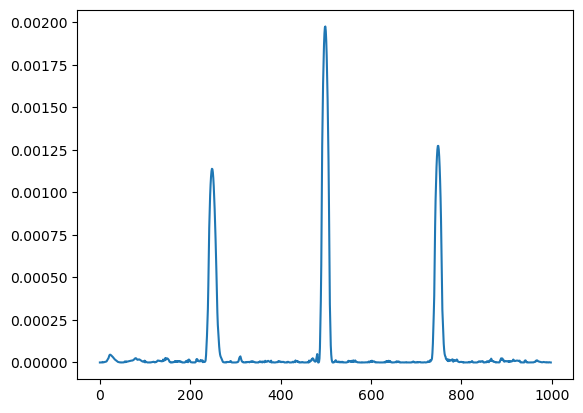

In [28]:
plt.plot(init_data["theta"])
plt.show()

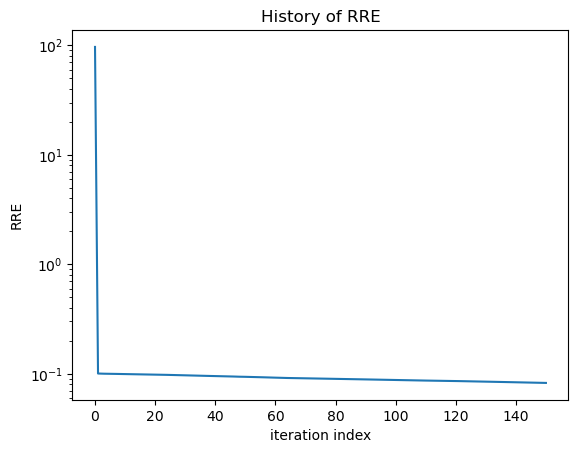

In [29]:
plt.plot(init_data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

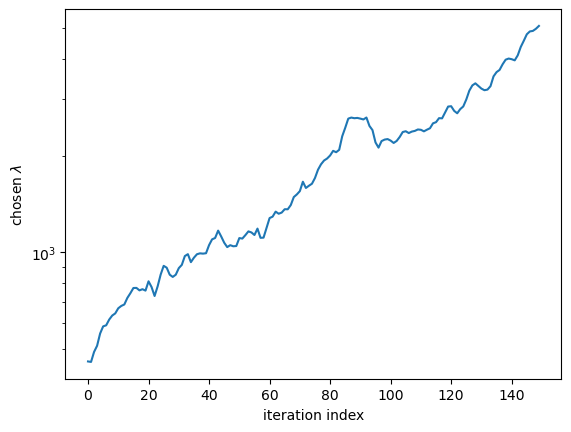

In [30]:
plt.plot(init_data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

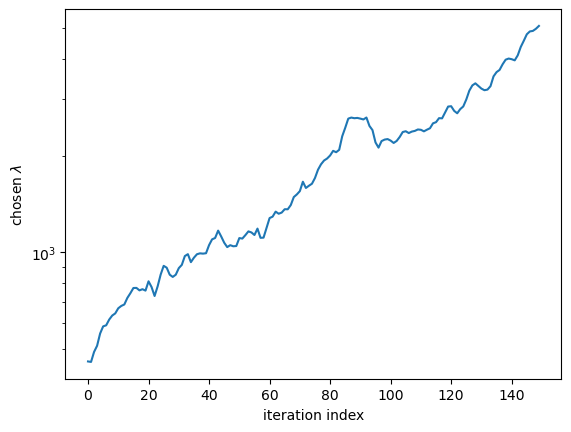

In [31]:
plt.plot(init_data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

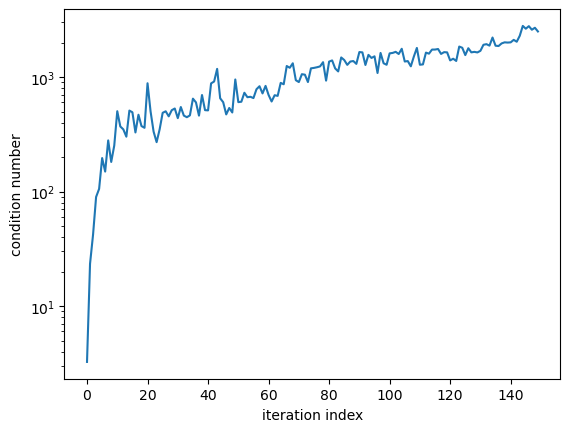

In [32]:
plt.plot(init_data["cond_ests"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("condition number")
plt.show()

# Now do nonconvex solve

In [33]:
final_gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=noise_var)
final_data = final_gksias_solver.solve(n_iter=150, hyperpr_r=-1.0, hyperpr_beta=1.0, x_true=ground_truth, x0=init_data["x"], regparam="dp3", tol=1e-5)

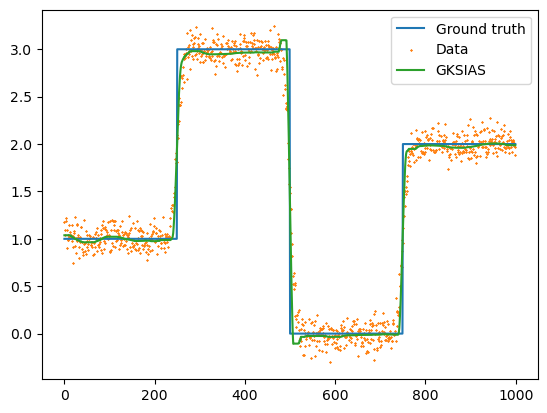

In [38]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, final_data["x"], label="GKSIAS", color="C2")
plt.legend()
plt.show()

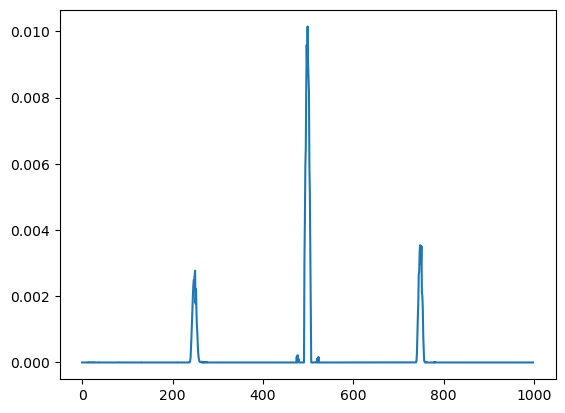

In [39]:
plt.plot(final_data["theta"])
plt.show()

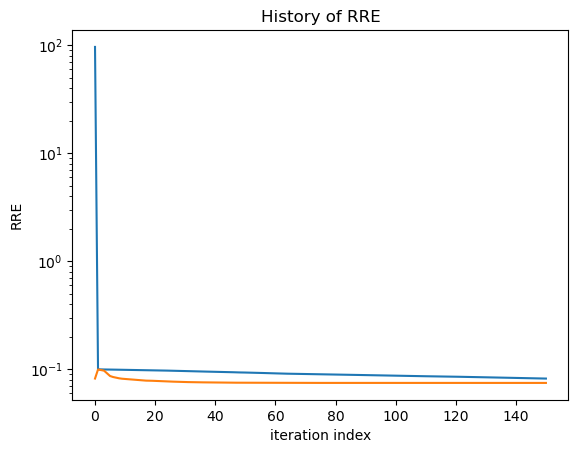

In [41]:
plt.plot(init_data["rre_history"])
plt.plot(final_data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

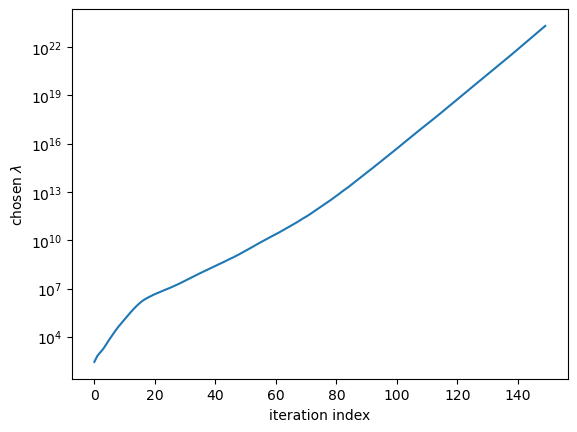

In [42]:
plt.plot(final_data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()